# Figure 6: ANN vs. linear models

Median per-trajectory heading error of the ANN and of the best linear OLS, circular OLS and Möbius (free-slope circular) regression baselines, overall and in each flight regime. This is `figures/ann_vs_linear_models_summary` (section 4 of `03_ann_vs_linear_models.ipynb`) redrawn in the style of Figures 1, 3 and 4. It also shows notebook 03's section 5 (`figures/ann_vs_linear_models_summary_conf0.99`): the same models scored only on the held-out frames whose heading correction is confident (`heading_confidence > 0.99`).

**Requires** `01_data_correction_and_processing.ipynb` (it reads `04_trainingdata/`) and `02_training_and_testing_the_ann.ipynb` (it reads the ANN's per-frame held-out errors, `tables/ann_by_regime.csv`). The split is that of notebooks 02 and 03 (trajectory-grouped, seed 42, 33 % test).

**Output**: `publication_figures/figure_6.svg`, a [figurefirst](https://github.com/FlyRanch/figurefirst) layout on a letter page, built like `publication_figures/figure_3.svg` and `publication_figures/figure_4.svg`. Its template layer ("Layer 1", hidden in the output) holds one rectangle per panel, each a figurefirst axis, in one figurefirst figure, `summary`:

- `errors`: the bar chart.
- `key`: what the wide and narrow bars show.

The notebook creates the layout if it does not exist and redraws the panels into the `summary` layer on every run. Changes made in Inkscape to the rectangles (moving or resizing them) or to other layers are kept.

**Graphics**:
- **Wide bars** (light): all held-out frames, as in `ann_vs_linear_models_summary`. Median over trajectories of each trajectory's median frame error (line across the bar, value written above it), with the 95 % bootstrap CI (resampling trajectories) as a darker band.
- **Narrow bars** (dark, inside the wide bars): only the held-out frames with heading confidence > 0.99, as in `ann_vs_linear_models_summary_conf0.99`, with the 95 % CI as a black line. Nothing is refit: same baselines (fit on all training frames, selected by pooled error on all held-out frames) and the full-training-set ANN. Each trajectory's error is the median over its confident frames; trajectories without a confident frame (in a regime) drop out, so the narrow bars rest on fewer trajectories (the tick labels give both counts).
- **Regimes** come from the true heading relative to the wind (toward +x): downwind within 45° of 0°, upwind within 45° of 180°, crosswind otherwise. A trajectory counts in every regime it visits.
- **Colours**: the ANN is purple, as its heading in Figures 4 and 5.

## Setup

In [1]:
import os
import sys
import warnings
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
from matplotlib.legend_handler import HandlerBase
from matplotlib.patches import Rectangle
from IPython.display import SVG, display
from scipy.optimize import minimize
from sklearn.model_selection import GroupShuffleSplit

with warnings.catch_warnings():
    warnings.simplefilter('ignore')   # figurefirst emits SyntaxWarnings on import under Python 3.12
    import figurefirst as fifi

sys.path.insert(0, os.path.abspath('../utils'))
from utils import circular_distance

plt.rcParams['svg.fonttype'] = 'none'   # keep text editable in Inkscape
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans']

LAYOUT_PATH = '../publication_figures/figure_6.svg'
DATA_PATH = '../trainingdata/04_trainingdata/all_wind_heading_and_trajectories_augmented_corrected_filtered_headx_heady.csv'
RESULTS = '../tables/'
CONF_THRESHOLD = 0.99

/Users/florisvb/src/drosophila_body_orientation_predictor/.venv/lib/python3.12/site-packages/pynumdiff/__init__.py:9: UserWarning: tvrdiff, robustdiff, and lineardiff not available due to lack of convex solver. To use those, install CVXPY.
  warn("tvrdiff, robustdiff, and lineardiff not available due to lack of convex solver. To use those, install CVXPY.")


## Layout

Letter page in Inkscape's default user units (96 px/in), with the panels spanning `FIG_W` = 6.5 in, centred on the page: the bar chart, and the key in the empty space above the overall and upwind bars. Each rectangle is the plotting area of its axes: tick labels and axis labels go outside it, in the gaps left for them (`YLABEL_IN`). Set `OVERWRITE_LAYOUT = True` to regenerate the layout from these constants. This discards any edits made to the file in Inkscape.

In [2]:
OVERWRITE_LAYOUT = False

PX_PER_IN = 96
PAGE_W, PAGE_H = 8.5, 11.0         # in
FIG_W = 6.5                        # in, width spanned by the panels
LEFT, TOP = (PAGE_W - FIG_W) / 2, 1.0
YLABEL_IN = 0.45                   # room left of the bar chart for its tick labels and y-axis label (in)
ERR_H = 2.2                        # bar chart height (in)
KEY_X, KEY_W, KEY_H = 1.6, 1.5, 0.45   # key: offset from the bar chart's left edge, width and height (in)


def panel_rects():
    '''{figure name: [(axis name, x, y, w, h), ...]} in inches from the page's top left corner'''
    x = LEFT + YLABEL_IN
    return {'summary': [('errors', x, TOP, FIG_W - YLABEL_IN, ERR_H),
                        ('key', x + KEY_X, TOP + 0.05, KEY_W, KEY_H)]}


def group_svg(figure, rects):
    '''A figurefirst figure: a group of rectangles, each a figurefirst axis'''
    out = [f'    <g id="{figure}_template">', f'      <figurefirst:figure figurefirst:name="{figure}" />']
    for name, x, y, w, h in rects:
        out.append(f'      <rect id="{name}" x="{x * PX_PER_IN:g}" y="{y * PX_PER_IN:g}" width="{w * PX_PER_IN:g}" '
                   f'height="{h * PX_PER_IN:g}" style="fill:none;stroke:#000000;stroke-width:1">\n'
                   f'        <figurefirst:axis figurefirst:name="{name}" />\n'
                   f'      </rect>')
    return '\n'.join(out) + '\n    </g>\n'


def make_layout_svg(path):
    groups = ''.join(group_svg(figure, rects) for figure, rects in panel_rects().items())
    svg = f'''<?xml version="1.0" encoding="UTF-8" standalone="no"?>
<svg
   xmlns="http://www.w3.org/2000/svg"
   xmlns:svg="http://www.w3.org/2000/svg"
   xmlns:inkscape="http://www.inkscape.org/namespaces/inkscape"
   xmlns:sodipodi="http://sodipodi.sourceforge.net/DTD/sodipodi-0.dtd"
   xmlns:figurefirst="http://flyranch.github.io/figurefirst/"
   width="{PAGE_W}in"
   height="{PAGE_H}in"
   viewBox="0 0 {PAGE_W * PX_PER_IN:g} {PAGE_H * PX_PER_IN:g}"
   version="1.1"
   id="svg1">
  <sodipodi:namedview id="namedview1" inkscape:document-units="in" />
  <g inkscape:groupmode="layer" inkscape:label="Layer 1" id="layer1">
{groups}  </g>
</svg>
'''
    with open(path, 'w') as f:
        f.write(svg)


os.makedirs(os.path.dirname(LAYOUT_PATH), exist_ok=True)
if OVERWRITE_LAYOUT or not os.path.exists(LAYOUT_PATH):
    make_layout_svg(LAYOUT_PATH)
    print(f'Wrote layout {LAYOUT_PATH}')
else:
    print(f'Using existing layout {LAYOUT_PATH}')

Using existing layout ../publication_figures/figure_6.svg


## Data and split

As in notebook 03. The ANN's per-frame held-out errors (`tables/ann_by_regime.csv`) are in the order of the held-out frames here; the check below stops the notebook if they come from different data or a different split.

In [3]:
TWO_PI = 2 * np.pi
REGIMES = ['upwind', 'crosswind', 'downwind']
GROUPS = ['overall'] + REGIMES

data = pd.read_csv(DATA_PATH)
ids = data['trajec_objid'].unique()
tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.33, random_state=42).split(np.zeros((len(ids), 1)), groups=ids))
train_ids, test_ids = set(ids[tr]), set(ids[te])
train_df = data[data['trajec_objid'].isin(train_ids)].reset_index(drop=True)
test_df = data[data['trajec_objid'].isin(test_ids)].reset_index(drop=True)
print(f'{len(ids)} trajectories, {len(data)} frames | train {len(train_ids)} / test {len(test_ids)} trajectories')

ann_frames = pd.read_csv(RESULTS + 'ann_by_regime.csv')
assert len(ann_frames) == len(test_df) and (ann_frames['trajec_objid'].values == test_df['trajec_objid'].values).all(), \
    'tables/ann_by_regime.csv does not match this split: re-run 02_training_and_testing_the_ann.ipynb on the current data'

conf_mask = (test_df['heading_confidence'] > CONF_THRESHOLD).values
print(f'{conf_mask.sum()} of {len(test_df)} held-out frames ({100 * conf_mask.mean():.1f} %) have confidence > {CONF_THRESHOLD}, '
      f'in {test_df.loc[conf_mask, "trajec_objid"].nunique()} of {len(test_ids)} trajectories')

3321 trajectories, 112083 frames | train 2225 / test 1096 trajectories
30170 of 36942 held-out frames (81.7 %) have confidence > 0.99, in 957 of 1096 trajectories


## Baselines

Copied from notebook 03: the 14 linear and circular OLS baselines (thrust, airspeed, groundspeed and every combination) and the three Möbius regressions, fit on the training trajectories. The best of each family is the one with the lowest median per-trajectory error on all held-out frames.

In [4]:
QUANT = {'thrust': ('thrust', 'thrust_angle'), 'air': ('airspeed', 'airspeed_angle'), 'ground': ('groundspeed', 'groundspeed_angle')}


def circ_mean(a): return np.arctan2(np.sin(a).mean(), np.cos(a).mean())
def mobius(x, mu, nu, lb): return mu + 2 * np.arctan(np.exp(lb) * np.tan((x - nu) / 2))


def fit_mobius(x, y):
    best = None
    for nu0 in np.linspace(0, TWO_PI, 8, endpoint=False):
        for lb0 in (-1.0, 0.0, 1.0, 2.0):
            r = minimize(lambda p: np.mean(1 - np.cos(y - mobius(x, *p))), [circ_mean(y - x), nu0, lb0],
                         method='Nelder-Mead', options=dict(xatol=1e-6, fatol=1e-10, maxiter=4000))
            if best is None or r.fun < best.fun: best = r
    return best.x


def design(d, combo, kind):
    cols = [np.ones(len(d))]
    for q in combo:
        m, a = QUANT[q]
        if kind == 'linear': cols += [d[m].values * np.cos(d[a].values), d[m].values * np.sin(d[a].values)]
        else:                cols += [np.cos(d[a].values), np.sin(d[a].values)]
    return np.column_stack(cols)


def ols_angle(train, test, combo, kind):
    coef = np.linalg.lstsq(design(train, combo, kind), train[['heading_angle_x', 'heading_angle_y']].values, rcond=None)[0]
    p = design(test, combo, kind) @ coef
    return np.arctan2(p[:, 1], p[:, 0])


def mobius_angle(train, test, q):
    a = QUANT[q][1]
    return mobius(test[a].values, *fit_mobius(train[a].values, train['heading_angle'].values))


def classify_direction(a):
    deg = np.degrees(np.arctan2(np.sin(a), np.cos(a)))
    return np.where(np.abs(deg) <= 45, 'downwind', np.where(np.abs(np.abs(deg) - 180) <= 45, 'upwind', 'crosswind'))


def frame_errors(test, pred_angle):
    err = np.degrees(circular_distance(test['heading_angle'].values, pred_angle))
    return pd.DataFrame({'trajec_objid': test['trajec_objid'].values, 'err': err, 'regime': classify_direction(test['heading_angle'].values)})


def trajectory_errors(fdf):
    '''{group: per-trajectory median error}, pooled over all frames ('overall') and within each regime'''
    out = {'overall': fdf.groupby('trajec_objid')['err'].median()}
    for r in REGIMES:
        out[r] = fdf[fdf['regime'] == r].groupby('trajec_objid')['err'].median()
    return out


frames = {}   # model -> per-frame held-out errors
for n in range(1, 4):
    for combo in combinations(QUANT, n):
        for kind in ('linear', 'circular'):
            frames[f'{kind}: {"+".join(combo)}'] = frame_errors(test_df, ols_angle(train_df, test_df, combo, kind))
for q in QUANT:
    frames[f'mobius: {q}'] = frame_errors(test_df, mobius_angle(train_df, test_df, q))
overall = {k: f.groupby('trajec_objid')['err'].median().median() for k, f in frames.items()}
BEST = {fam: min((k for k in frames if k.startswith(fam)), key=overall.get) for fam in ('linear', 'circular', 'mobius')}
print('best by median per-trajectory error on all held-out frames:', BEST)

best by median per-trajectory error on all held-out frames: {'linear': 'linear: thrust+air+ground', 'circular': 'circular: air+ground', 'mobius': 'mobius: air'}


## Errors

Median per-trajectory error with its 95 % bootstrap CI (5000 resamples of trajectories, as in notebook 03), on all held-out frames and on the confident ones.

In [5]:
def bootstrap_ci(v, n_boot=5000, seed=0):
    v = np.asarray(v); rng = np.random.default_rng(seed)
    med = np.median(rng.choice(v, size=(n_boot, len(v)), replace=True), axis=1)
    lo, hi = np.percentile(med, [2.5, 97.5]); return float(np.median(v)), float(lo), float(hi)


MODELS = {BEST['linear']: frames[BEST['linear']], BEST['circular']: frames[BEST['circular']],
          BEST['mobius']: frames[BEST['mobius']], 'ANN': ann_frames}
summary = {}   # (model, frames, group) -> (median, ci lo, ci hi, n trajectories)
for key, fdf in MODELS.items():
    for which, f in (('all', fdf), ('conf', fdf[conf_mask])):
        for g, v in trajectory_errors(f).items():
            summary[key, which, g] = (*bootstrap_ci(v.values), len(v))

table = pd.DataFrame([{'Model': key, 'Frames': 'all' if which == 'all' else f'confidence > {CONF_THRESHOLD}',
                       **{g.capitalize(): f'{m:.2f} [{lo:.2f}, {hi:.2f}]' for g in GROUPS for m, lo, hi, _ in [summary[key, which, g]]}}
                      for which in ('all', 'conf') for key in MODELS])
print('Median per-trajectory error (deg) [95% CI]:')
display(table)
print('trajectories per group (all / confident):',
      {g: (summary['ANN', 'all', g][3], summary['ANN', 'conf', g][3]) for g in GROUPS})

Median per-trajectory error (deg) [95% CI]:


,Model,Frames,Overall,Upwind,Crosswind,Downwind
0,linear: thrust+air+ground,all,"9.49 [8.63, 10.51]","5.56 [5.05, 6.06]","31.28 [28.84, 33.50]","41.28 [37.12, 47.79]"
1,circular: air+ground,all,"9.42 [8.42, 10.69]","6.25 [5.88, 6.78]","35.07 [33.23, 36.86]","22.54 [17.30, 29.69]"
2,mobius: air,all,"8.32 [7.78, 9.03]","7.05 [6.61, 7.60]","26.32 [23.87, 29.26]","21.13 [18.07, 27.83]"
3,ANN,all,"4.96 [4.65, 5.44]","5.08 [4.80, 5.70]","20.16 [16.79, 23.86]","5.64 [4.31, 7.27]"
4,linear: thrust+air+ground,confidence > 0.99,"6.97 [6.36, 7.68]","4.90 [4.58, 5.24]","24.82 [23.32, 26.35]","26.45 [24.22, 33.58]"
5,circular: air+ground,confidence > 0.99,"7.11 [6.55, 8.14]","5.41 [4.73, 5.77]","29.55 [27.97, 30.64]","10.73 [8.31, 13.94]"
6,mobius: air,confidence > 0.99,"6.95 [6.39, 7.28]","6.31 [5.84, 6.71]","18.96 [16.49, 21.49]","10.82 [7.45, 16.10]"
7,ANN,confidence > 0.99,"4.46 [4.13, 4.79]","4.59 [4.19, 4.88]","11.85 [9.92, 15.36]","3.35 [2.70, 4.27]"


trajectories per group (all / confident): {'overall': (1096, 957), 'upwind': (903, 821), 'crosswind': (614, 478), 'downwind': (242, 111)}


## Plotting

Font size and line widths follow Figures 1, 3 and 4. Each model has a light and a dark shade of one colour: light for the wide bar (all held-out frames), dark for the narrow bar (confident frames). The ANN's are the purples of its heading in Figures 4 and 5.

In [6]:
FONTSIZE = 7
SLOT = 0.2                 # spacing between a group's bars (x units; groups are 1 apart)
WIDE = 0.17                # bar width, all held-out frames (x units)
NARROW = 0.07              # bar width, confident frames (x units)
YMAX = 50                  # deg
# (model, legend label, light shade, dark shade)
STYLE = [(BEST['linear'], 'Best linear OLS', '#d4d7db', '#7b828a'),
         (BEST['circular'], 'Best circular OLS', '#b8c6d6', '#405a78'),
         (BEST['mobius'], 'Best Möbius regression', '#f6c9a4', '#c8641e'),
         ('ANN', 'ANN', '#b9a3dc', '#3f1a73')]
BAND_MIX = 0.35            # CI band of the wide bars: this far from the light shade to the dark one
CI_LW = 0.6                # CI line of the narrow bars, and median line of the wide bars


def style_axes(ax, title=None):
    if title:
        ax.set_title(title, fontsize=FONTSIZE, pad=4)
    ax.tick_params(labelsize=FONTSIZE - 1, length=2, width=0.5)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    for side in ('left', 'bottom'):
        ax.spines[side].set_linewidth(0.5)


def mix(light, dark, f):
    return (1 - f) * np.array(mcolors.to_rgb(light)) + f * np.array(mcolors.to_rgb(dark))


def nested_bar(ax, x, light, dark, all_, conf, wide=WIDE, narrow=NARROW):
    '''Wide bar (all frames): light up to its CI, then the CI as a darker band with the median as a line across it.
    Narrow bar (confident frames) on top: dark up to the median, with the CI as a black line.'''
    (m, lo, hi), (mc, loc, hic) = all_, conf
    ax.add_patch(Rectangle((x - wide / 2, 0), wide, lo, fc=light, lw=0, zorder=1))
    ax.add_patch(Rectangle((x - wide / 2, lo), wide, hi - lo, fc=mix(light, dark, BAND_MIX), lw=0, zorder=1))
    ax.plot([x - wide / 2, x + wide / 2], [m, m], color=dark, lw=CI_LW, solid_capstyle='butt', zorder=2)
    ax.add_patch(Rectangle((x - narrow / 2, 0), narrow, mc, fc=dark, lw=0, zorder=3))
    ax.plot([x, x], [loc, hic], color='black', lw=CI_LW, solid_capstyle='butt', zorder=4)


class NestedBarKey:
    def __init__(self, light, dark): self.light, self.dark = light, dark


class NestedBarHandler(HandlerBase):
    '''Legend handle: a wide light bar with a narrow dark bar inside'''
    def create_artists(self, legend, handle, xdescent, ydescent, width, height, fontsize, trans):
        nw = width * NARROW / WIDE
        return [Rectangle((-xdescent, -ydescent), width, height, fc=handle.light, lw=0, transform=trans),
                Rectangle((-xdescent + (width - nw) / 2, -ydescent), nw, 0.75 * height, fc=handle.dark, lw=0, transform=trans)]


def plot_errors(ax):
    for i, (key, label, light, dark) in enumerate(STYLE):
        for g_i, g in enumerate(GROUPS):
            x = g_i + (i - 1.5) * SLOT
            nested_bar(ax, x, light, dark, summary[key, 'all', g][:3], summary[key, 'conf', g][:3])
            m, _, hi, _ = summary[key, 'all', g]
            ax.text(x, hi + 0.6, f'{m:.1f}', ha='center', va='bottom', fontsize=FONTSIZE - 2)
    ax.set_xlim(-0.5, len(GROUPS) - 0.5); ax.set_ylim(0, YMAX)
    ax.set_xticks(range(len(GROUPS)), [f'{g.capitalize()}\nn = {summary["ANN", "all", g][3]} ({summary["ANN", "conf", g][3]})'
                                       for g in GROUPS])
    ax.set_ylabel('Median per-trajectory error (°)', fontsize=FONTSIZE)
    ax.legend([NestedBarKey(light, dark) for _, _, light, dark in STYLE], [label for _, label, _, _ in STYLE],
              handler_map={NestedBarKey: NestedBarHandler()}, loc='upper left', frameon=False, fontsize=FONTSIZE - 1,
              handlelength=0.9, handleheight=1.4, borderaxespad=0.2)
    style_axes(ax)
    ax.tick_params(axis='x', length=0)


def plot_key(ax):
    '''One grey example bar, labelled'''
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis('off')
    w = 0.13   # wide bar width (axes fraction)
    _, _, light, dark = STYLE[0]
    nested_bar(ax, w / 2, light, dark, (0.85, 0.75, 0.95), (0.45, 0.35, 0.55), wide=w, narrow=w * NARROW / WIDE)
    kw = dict(fontsize=FONTSIZE - 1, va='center', ha='left')
    ax.text(w + 0.05, 0.85, 'All held-out frames: median (line), 95% CI (band)', **kw)
    ax.text(w + 0.05, 0.45, f'Heading confidence > {CONF_THRESHOLD}: median, 95% CI (line)', **kw)
    ax.plot([w / 2 + w * NARROW / WIDE / 2, w + 0.04], [0.45, 0.45], color='black', lw=0.4)
    ax.text(w + 0.05, 0.05, 'n = trajectories: all (confident)', **kw)

## Draw the figure

The panels are written into the `summary` layer of `publication_figures/figure_6.svg`, which is cleared first.

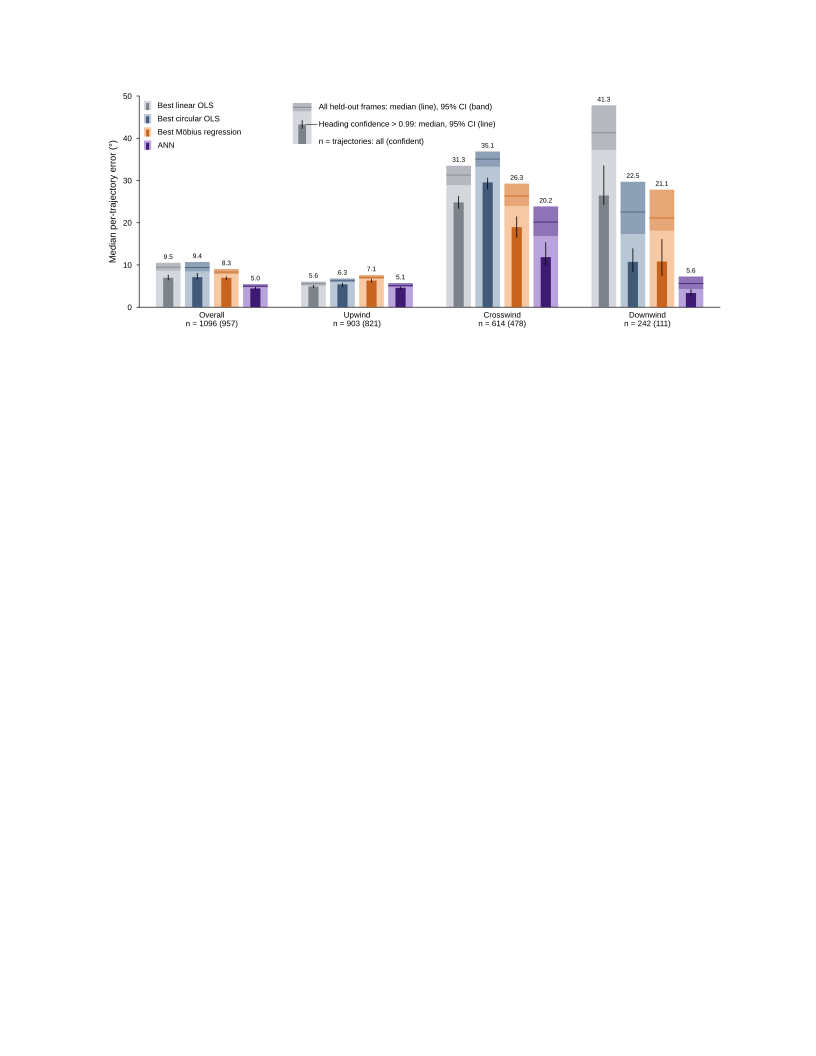

In [7]:
FIGURE = 'summary'
layout = fifi.FigureLayout(LAYOUT_PATH, autogenlayers=True, make_mplfigures=True)
plot_errors(layout.axes[(FIGURE, 'errors')])
plot_key(layout.axes[(FIGURE, 'key')])
layout.append_figure_to_layer(layout.figures[FIGURE], FIGURE, cleartarget=True)

layout.write_svg(LAYOUT_PATH)
plt.close('all')
display(SVG(LAYOUT_PATH))